## This is a test

In [10]:
import numpy as np
from src.metamaterial.config import SimulationConfig
from src.metamaterial.calculation import calculate
import matplotlib.pyplot as plt

In [11]:
name='test retarded'
R = 0.002
L = 13.459 * 10 ** -9
C = 470 * 10 ** -10
radius = 4.935 * 10 ** -3
width = 0
Dx = Dy = Dz = 15 * 10 ** -3
orientations = 'zyx'
type = 'border'
Nx, Ny, Nz = 10, 10, 10
packing = 'ellipse'
interaction_model = 'full_retarded'
H_0 = 1
H_direction = (0, 0, 1)
k_direction = (1, 0, 0)
omega_0 = 1 / np.sqrt(L * C)
omegas = np.linspace(omega_0*0.9, omega_0*1.1, 20)
solver = 'straight'
save_currents = True
save_polarizability = False
save_extinction_cross_section = True

In [ ]:
config = SimulationConfig(name=name, R=R, L=L, C=C, radius=radius, width=width, Dx=Dx, Dy=Dy, Dz=Dz,
                          orientations=orientations, type=type, Nx=Nx, Ny=Ny, Nz=Nz, packing=packing, interaction_model=interaction_model,
                          H_0=H_0, H_direction=H_direction, k_direction=k_direction, omegas=omegas, solver=solver, save_currents=save_currents, save_polarizability=save_polarizability, save_extinction_cross_section=save_extinction_cross_section)
calculate(config)

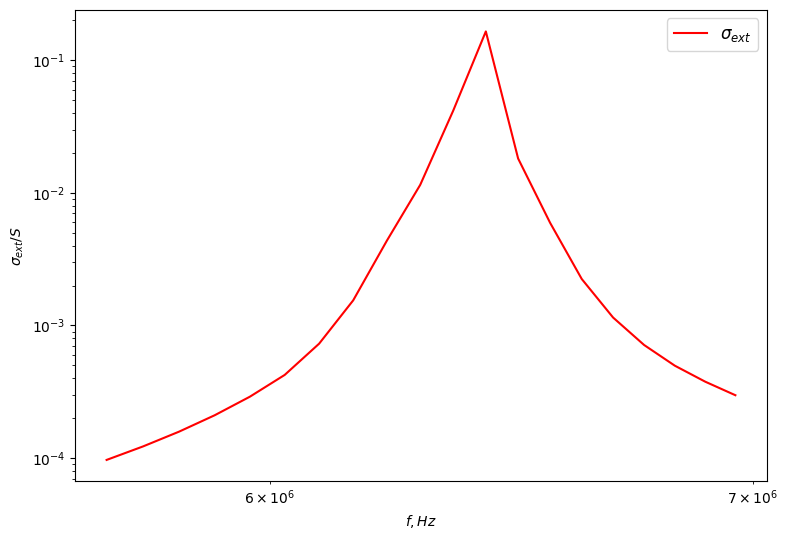

In [15]:
p = np.load(f'DATA/{name}/extinction_cross_section.npy')
fig1, ax1 = plt.subplots(figsize=(8, 5.5))

ax1.plot(omegas/(2*np.pi), np.abs(p)/(Dx*Dy*10*10), markersize=4,
         label=r'$\sigma_{ext}$', color='red')

ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_xlabel(r'$f, Hz$')
ax1.set_ylabel(r'$\sigma_{ext}/S$')
ax1.legend(fontsize=12)

plt.tight_layout()
plt.show()

In [5]:
from src.metamaterial.visualization.visualization import plot_geometry
from src.metamaterial.geometry import build_geometry

geometry = build_geometry(config)
fig = plot_geometry(
    geometry=geometry,
    config=config,
    orientations=("x", "y", "z"),
)
fig.show()